In [1]:
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
print("Added to path:", os.path.abspath(os.path.join(os.getcwd(), "..", "..")))

import os
os.environ["WIKI_FAISS_INDEX_DIR"] = "/teamspace/studios/this_studio/wiki_faiss"
os.environ["WIKI_TEXT_DIR"] = "/teamspace/studios/this_studio/wiki_text"

import numpy as np
import torch, random
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

from src.dataset.data_loader import load_competition_data, load_rag_resources, load_retriever
from src.models.BiGRU_Rag_scratch import (
    OPTIONS, build_rag_context, build_vocab, MCQDataset, OptionScorer,
)
from src.inference.BiGRU_Rag_inference import (
    train_bigru_rag, predict_top3, save_submission,
)

SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Added to path: /teamspace/studios/this_studio/genAI-project-24f1002692


Using device: cuda


In [2]:
# Load competition data + RAG resources (Wikipedia FAISS index + retriever)
train_dataset, test_dataset, sample_submission = load_competition_data()
wiki_index, wiki_index_df = load_rag_resources()
retriever = load_retriever()

import faiss
res = faiss.StandardGpuResources()
wiki_index = faiss.index_cpu_to_gpu(res, 0, wiki_index)
print("FAISS index moved to GPU")

Skipping import of cpp extensions due to incompatible torch version. Please upgrade to torch >= 2.11.0 (found 2.8.0+cu128).


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

FAISS index moved to GPU


In [4]:
# Prompt-level train/val split (prevents the same question leaking across both sets)
train_df = train_dataset.copy()
test_df = test_dataset.copy()

prompt_answer = train_df.groupby('prompt')['answer'].first()
unique_prompts = prompt_answer.index.values

train_prompts, val_prompts = train_test_split(
    unique_prompts, test_size=0.15, random_state=SEED, stratify=prompt_answer.values
)

train_split = train_df[train_df['prompt'].isin(train_prompts)].reset_index(drop=True)
val_split   = train_df[train_df['prompt'].isin(val_prompts)].reset_index(drop=True)

overlap = set(train_split['prompt']) & set(val_split['prompt'])
print(f"Train rows: {len(train_split)}  |  Val rows: {len(val_split)}  |  Prompt overlap: {len(overlap)}")

Train rows: 1701  |  Val rows: 299  |  Prompt overlap: 0


In [5]:
# Build RAG context for each split (retrieves top-3 Wikipedia passages per prompt)
print(retriever.device)
print(" ")
train_split['rag_context'] = build_rag_context(train_split, retriever, wiki_index, wiki_index_df)
val_split['rag_context']   = build_rag_context(val_split, retriever, wiki_index, wiki_index_df)
test_df['rag_context']     = build_rag_context(test_df, retriever, wiki_index, wiki_index_df)

cuda:0
 


retrieving context:   0%|          | 0/27 [00:00<?, ?it/s]

retrieving context: 100%|██████████| 8/8 [00:01<00:00,  5.62it/s]


In [6]:
# Build vocab from train split only, then wrap all 3 splits in MCQDataset + DataLoader
vocab = build_vocab(train_split)
print(f"Vocab size (with RAG context): {len(vocab)}")

train_loader = DataLoader(MCQDataset(train_split, vocab, augment=True), batch_size=32, shuffle=True)
val_loader   = DataLoader(MCQDataset(val_split, vocab, augment=False), batch_size=64, shuffle=False)
train_eval_loader = DataLoader(MCQDataset(train_split, vocab, augment=False), batch_size=64, shuffle=False)
test_loader  = DataLoader(MCQDataset(test_df, vocab, augment=False), batch_size=64, shuffle=False)

Vocab size (with RAG context): 5654


In [8]:
# Build model + train (checkpoints best val-MAP@3 model to best_scratch_rag_model.pt)
model = OptionScorer(vocab_size=len(vocab)).to(device)
print(model)

history, best_map3 = train_bigru_rag(
    model, train_loader, train_eval_loader, val_loader,
    train_split, val_split, device,
    epochs=25, use_wandb=False,
)

OptionScorer(
  (embedding): Embedding(5654, 100, padding_idx=0)
  (embed_drop): Dropout(p=0.4, inplace=False)
  (gru): GRU(100, 64, batch_first=True, bidirectional=True)
  (attn): Linear(in_features=128, out_features=1, bias=True)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


/teamspace/studios/this_studio/genAI-project-24f1002692/src/inference/BiGRU_Rag_inference.py:93: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ids, mask, labels = ids.to(device), mask.to(device), torch.tensor(labels).to(device)
/teamspace/studios/this_studio/genAI-project-24f1002692/src/inference/BiGRU_Rag_inference.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels_t = torch.tensor(labels).to(device)


/teamspace/studios/this_studio/genAI-project-24f1002692/src/inference/BiGRU_Rag_inference.py:36: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels_t = torch.tensor(labels).to(device)


Epoch  1 | train_loss 1.6092 | train MAP@3 0.4886 | val_loss 1.6057 | val MAP@3 0.4760


/teamspace/studios/this_studio/genAI-project-24f1002692/src/inference/BiGRU_Rag_inference.py:93: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ids, mask, labels = ids.to(device), mask.to(device), torch.tensor(labels).to(device)


Epoch  2 | train_loss 1.6035 | train MAP@3 0.5367 | val_loss 1.5978 | val MAP@3 0.5089
Epoch  3 | train_loss 1.5925 | train MAP@3 0.5662 | val_loss 1.5635 | val MAP@3 0.5535
Epoch  4 | train_loss 1.5564 | train MAP@3 0.6004 | val_loss 1.4298 | val MAP@3 0.5842
Epoch  5 | train_loss 1.5078 | train MAP@3 0.6727 | val_loss 1.3648 | val MAP@3 0.6327
Epoch  6 | train_loss 1.3978 | train MAP@3 0.7811 | val_loss 1.1517 | val MAP@3 0.7848
Epoch  7 | train_loss 1.3139 | train MAP@3 0.8530 | val_loss 1.0321 | val MAP@3 0.8506
Epoch  8 | train_loss 1.1978 | train MAP@3 0.8947 | val_loss 0.9102 | val MAP@3 0.8997
Epoch  9 | train_loss 1.1244 | train MAP@3 0.9136 | val_loss 0.8099 | val MAP@3 0.9320
Epoch 10 | train_loss 1.0347 | train MAP@3 0.9474 | val_loss 0.7579 | val MAP@3 0.9504
Epoch 11 | train_loss 0.9969 | train MAP@3 0.9643 | val_loss 0.6989 | val MAP@3 0.9649
Epoch 12 | train_loss 0.9344 | train MAP@3 0.9609 | val_loss 0.6678 | val MAP@3 0.9643
Epoch 13 | train_loss 0.8836 | train MAP@3 

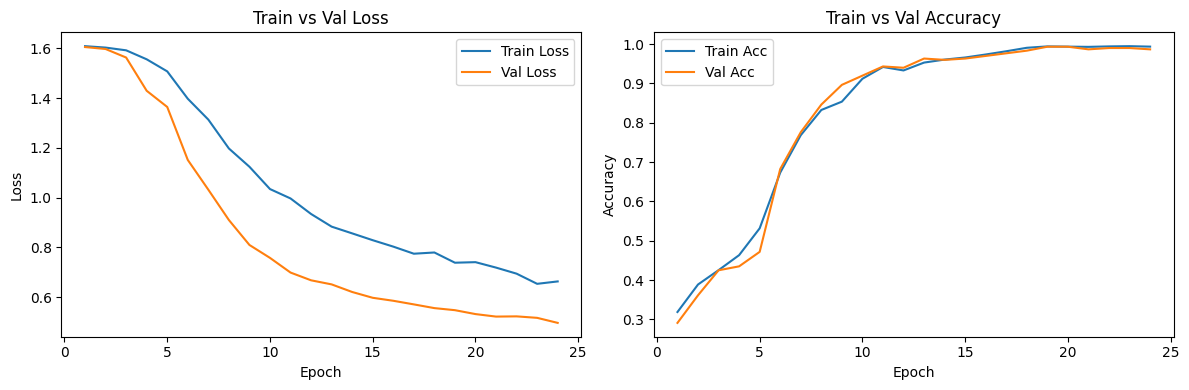

In [10]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss plot
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Train vs Val Loss")
axes[0].legend()

# Accuracy plot
axes[1].plot(epochs_range, history["train_acc"], label="Train Acc")
axes[1].plot(epochs_range, history["val_acc"], label="Val Acc")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Train vs Val Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [11]:
# Load best checkpoint, predict on test.csv, save Kaggle submission
model.load_state_dict(torch.load("best_scratch_rag_model.pt", map_location=device))

test_preds = predict_top3(model, test_loader, device)
submission = save_submission(test_df, test_preds, out_path="submission_scratch_rag.csv")
submission.head(10)

Saved: submission_scratch_rag.csv (500 rows)


,ID,Prediction
0,1,A E B
1,2,B C E
2,3,B E C
3,4,E D C
4,5,C D A
5,6,D B A
6,7,E C D
7,8,B E C
8,9,C D A
9,10,B A D
